# 💎 Diamond Price Prediction Using Machine Learning

# Explainable and Robust Diamond Price Prediction Using Machine Learning with What-If Analysis

## Project Overview

This project develops a machine-learning-based framework for diamond price prediction using a richer set of diamond characteristics.

The study investigates the effect of feature enrichment through systematic feature ablation, compares multiple regression models, evaluates model robustness using cross-validation, explains predictions using SHAP, and demonstrates controlled What-If analysis for individual diamond attributes.

The project also investigates selected feature-engineering approaches and hyperparameter optimization to determine whether they provide measurable improvements over the baseline feature representation.

The final system is intended to provide not only an estimated diamond price, but also interpretable information about the factors contributing to the prediction and a controlled mechanism for examining how changes in selected diamond characteristics affect the model's estimated price.

## Research Objective

The primary objective of this study is to investigate how the inclusion of richer diamond characteristics affects the performance of machine-learning-based diamond price prediction.

The study evaluates multiple regression algorithms under the same experimental conditions and investigates whether feature engineering and hyperparameter optimization can improve predictive performance.

In addition, the study evaluates model robustness using five-fold cross-validation, analyzes prediction errors, explains model predictions using SHAP, and demonstrates controlled What-If analysis for individual diamond characteristics.

The overall objective is to develop an applied and interpretable machine-learning framework that combines prediction, validation, explanation, and interactive price analysis.

## Research Questions

1. How much does prediction performance improve when moving from traditional 4C characteristics to a richer set of diamond features?

2. What is the contribution of physical dimensions and additional quality-related characteristics to diamond price prediction?

3. How do Linear Regression, Decision Tree, K-Nearest Neighbors, Random Forest, Gradient Boosting, and XGBoost compare when using the complete feature set?

4. Does feature engineering improve the performance of the selected Random Forest model?

5. Does hyperparameter optimization improve the predictive performance of the Random Forest model?

6. How consistent is the final model's performance across different cross-validation folds?

7. Which features contribute most strongly to individual model predictions?

8. How can What-If analysis be used to examine changes in model-predicted diamond prices under controlled changes to individual attributes?

## Literature-Based Research Gap

A review of previous diamond price prediction studies identified several recurring research directions and opportunities.

1. **Feature coverage:** Previous studies frequently focus on conventional diamond characteristics such as carat, cut, color, and clarity, while some recent studies investigate additional physical and quality-related characteristics.

2. **Feature engineering and interaction:** Existing research has investigated derived features and interaction terms. Therefore, this study evaluates feature engineering experimentally rather than assuming that additional features will necessarily improve prediction.

3. **Model comparison:** Regression model comparison is common in the existing literature. In this study, model comparison is used as the experimental foundation for identifying a suitable prediction model rather than being treated as the sole contribution.

4. **Generalization and robustness:** Many studies evaluate models using a single dataset and train-test evaluation. This study additionally uses five-fold cross-validation to examine performance consistency across different data partitions.

5. **Interpretability:** A predicted price alone does not explain why a particular diamond receives a specific estimated price. SHAP-based analysis is therefore used to investigate feature contributions.

6. **Practical interaction:** A controlled What-If analysis allows changes to selected diamond characteristics to be examined through the trained model without manually fixing the resulting price difference.

### Research Response

This study addresses these directions through a controlled experimental framework that combines:

- Feature-set ablation from traditional 4C characteristics to a richer 17-feature representation.
- Comparison of six regression algorithms under consistent evaluation conditions.
- Investigation of derived and interaction-based feature engineering.
- Hyperparameter optimization of the selected Random Forest model.
- Five-fold cross-validation for robustness assessment.
- Error analysis of the final model.
- SHAP-based model explanation.
- Controlled What-If analysis for individual predictions.

## Dataset Description

The dataset used in this study is a diamond marketplace dataset containing detailed information about individual diamonds.

The original dataset contains **6,485 records and 18 features**. After removing **3 exact duplicate records**, the final dataset contains **6,482 records**.

The dataset includes traditional diamond characteristics as well as additional physical, quality, and market-related attributes.

### Feature Groups

**Traditional 4C-related features:**
- Carat Weight
- Cut
- Color
- Clarity

**Diamond dimensions:**
- Length
- Width
- Height
- Depth %
- Table %
- Length/Width Ratio

**Physical and quality characteristics:**
- Polish
- Symmetry
- Girdle
- Culet
- Fluorescence
- Shape

**Additional information:**
- Type
- Price

The target variable for this study is **Price**, while the remaining attributes are used as input features for machine-learning-based price prediction.

The dataset contains missing values, particularly in some categorical quality-related attributes. These missing values are handled through a preprocessing pipeline rather than being removed directly.

### Research Relevance

The availability of both traditional diamond characteristics and additional physical and quality-related attributes makes this dataset suitable for investigating whether a richer feature representation can improve price prediction performance.

Therefore, the dataset is used not only for model comparison but also for the **feature ablation experiment**, where prediction performance is compared across different feature groups.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

# Get the project root directory
PROJECT_ROOT = Path.cwd().parent

# Dataset path
DATA_PATH = PROJECT_ROOT / "data" / "diamonds (cleaned).csv"

print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

# Load dataset
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Dataset path: c:\Users\ishan\OneDrive\Desktop\Diamond-Price-Prediction\data\diamonds (cleaned).csv
File exists: True

Dataset loaded successfully.
Rows: 6485
Columns: 18


## Data Cleaning

Before applying any preprocessing or machine-learning algorithms, the dataset is examined for duplicate records, missing values, inconsistent representations, and other potential data-quality issues.

The objective of this stage is not to remove observations simply to improve model performance. Instead, each potential data-quality issue is evaluated based on whether it represents a genuine inconsistency or a valid observation.

### Duplicate Analysis

Duplicate records are identified by comparing complete rows across all available features.

Exact duplicate records, if present, are removed because they represent repeated observations of the same feature combination and can introduce unnecessary duplication during model training.

In [6]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 3


In [7]:
# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing exact duplicates:", df.shape)

Dataset shape after removing exact duplicates: (6482, 18)


### Duplicate Cleaning Result

The initial dataset contained **6,485 records**.

A total of **3 exact duplicate records** were identified and removed.

Therefore, the resulting dataset contains **6,482 unique records and 18 features**.

Only exact duplicates were removed at this stage. No observations were removed solely because of unusual prices, large carat weights, or other statistical characteristics, since such observations may represent legitimate diamonds and could contain useful information for evaluating model robustness.

## Missing Value Analysis

Missing values are examined before model training because incomplete observations can affect both exploratory analysis and machine-learning performance.

Instead of immediately removing rows containing missing values, the missing-value pattern is first quantified for each feature. This allows the study to distinguish between isolated missing observations and features with systematic missingness.

The analysis also considers missingness across different diamond types because a feature may be missing more frequently for particular categories of diamonds.

In [8]:
# Calculate missing-value statistics
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Fluorescence,5261,81.163221
Culet,4593,70.857760
Cut,4302,66.368405
Girdle,22,0.339401
Length,20,0.308547
Polish,20,0.308547
Height,20,0.308547
Symmetry,20,0.308547
Width,20,0.308547
Table %,17,0.262265


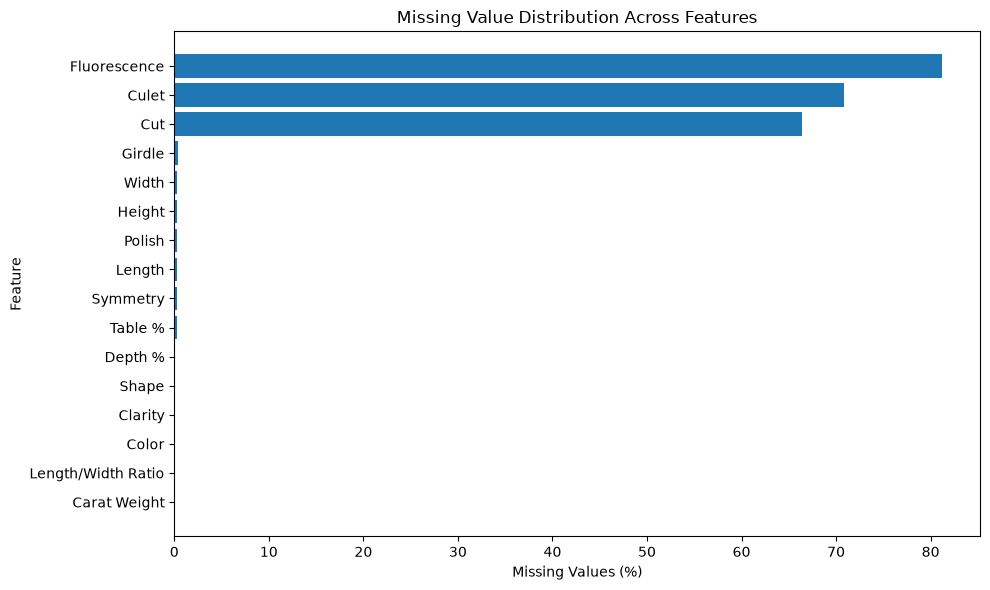

In [9]:
import matplotlib.pyplot as plt

missing_plot = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing Value Distribution Across Features")

plt.tight_layout()
plt.show()

### Missing Value Interpretation

The dataset contains missing values in several categorical quality-related features.

The highest levels of missingness are observed in **Fluorescence, Culet, and Cut**. These missing values are not automatically treated as erroneous observations because the absence of a recorded value may represent an unavailable or unreported characteristic.

Therefore, row-wise deletion is avoided because it could substantially reduce the dataset size and potentially introduce selection bias.

For categorical variables, missing values will later be represented using an explicit **"Unknown"** category. Numerical missing values will be imputed using statistics calculated from the training data only, preventing information leakage from the test set.

In [10]:
# Calculate missing percentage by diamond Type
missing_by_type = (
    df.groupby("Type")
      .apply(lambda x: x.isnull().mean() * 100, include_groups=False)
)

display(missing_by_type.round(2))

,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Price,Fluorescence
Type,,,,,,,,,,,,,,,,,
GIA,0.09,71.06,0.09,0.09,0.09,0.09,0.09,0.27,0.27,0.27,0.27,99.11,0.27,0.27,0.27,0.0,63.61
GIA Lab-Grown,0.00,43.81,0.00,0.00,0.00,0.00,0.00,0.24,0.48,0.48,0.56,100.00,0.48,0.48,0.48,0.0,100.00
IGI Lab-Grown,0.11,73.05,0.11,0.11,0.11,0.11,0.21,0.27,0.27,0.27,0.32,0.80,0.27,0.27,0.27,0.0,100.00


## Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of diamond prices, relationships between price and important numerical characteristics, and differences across categorical diamond attributes.

The analysis focuses on variables that are potentially relevant to price prediction, including carat weight, physical dimensions, color, clarity, shape, and diamond type.

The objective is to identify meaningful patterns in the dataset before applying machine-learning models. These observations are used to support the later feature-ablation, model-comparison, and error-analysis experiments.

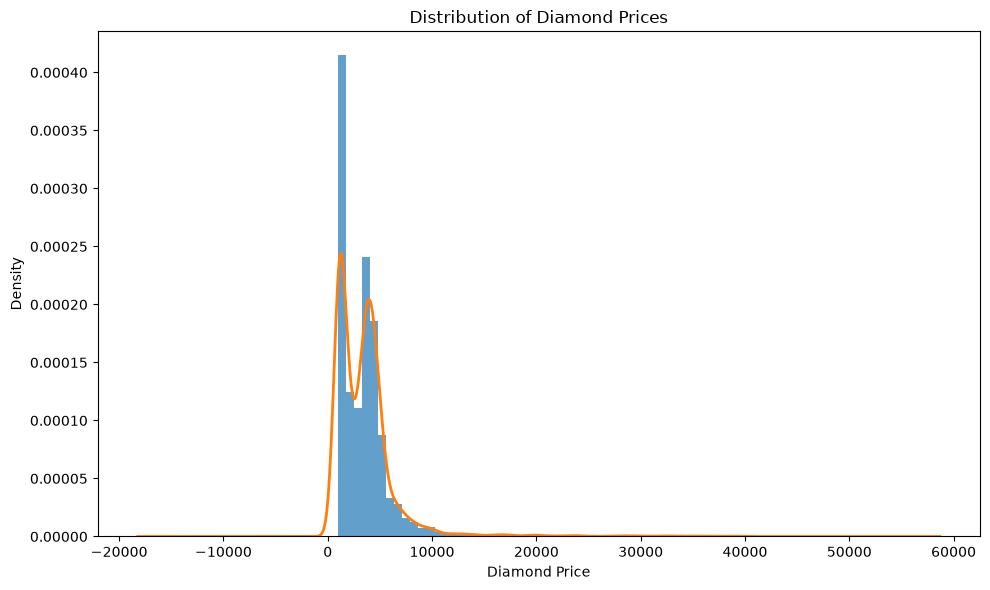

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df["Price"].dropna(),
    bins=50,
    density=True,
    alpha=0.7
)

df["Price"].dropna().plot(
    kind="kde",
    linewidth=2
)

plt.xlabel("Diamond Price")
plt.ylabel("Density")
plt.title("Distribution of Diamond Prices")

plt.tight_layout()
plt.show()

### Price Distribution Interpretation

The price distribution is strongly right-skewed, with most diamonds concentrated in the lower and middle price ranges and a smaller number of diamonds having substantially higher prices.

This long-tail structure indicates that price prediction is not a simple symmetric regression problem. High-priced observations can produce relatively large prediction errors and therefore require explicit evaluation during the later error-analysis stage.

The observed skewness also supports the use of evaluation metrics such as MAE, RMSE, and R² together rather than relying on a single performance measure.

<Figure size 1000x600 with 0 Axes>

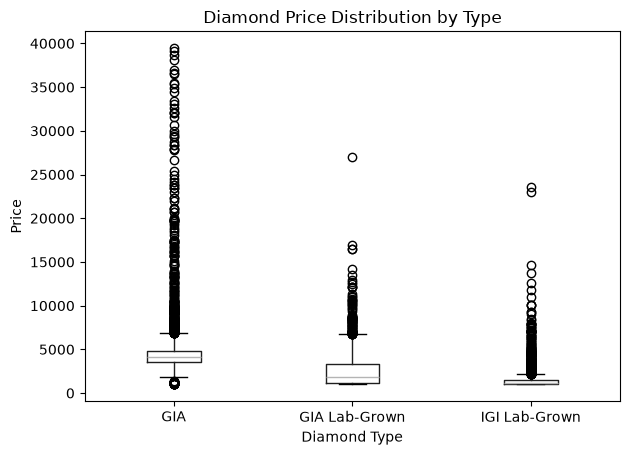

In [12]:
plt.figure(figsize=(10, 6))

df.boxplot(
    column="Price",
    by="Type",
    grid=False
)

plt.xlabel("Diamond Type")
plt.ylabel("Price")
plt.title("Diamond Price Distribution by Type")
plt.suptitle("")

plt.tight_layout()
plt.show()

### Price by Type Interpretation

The distribution of diamond prices differs substantially across the available diamond types.

The Type variable is therefore retained as an important predictor in the machine-learning experiments. Its contribution is examined further through model-based feature importance and SHAP analysis.

However, the observed differences should be interpreted as associations within this dataset rather than as evidence that Type alone determines diamond price.

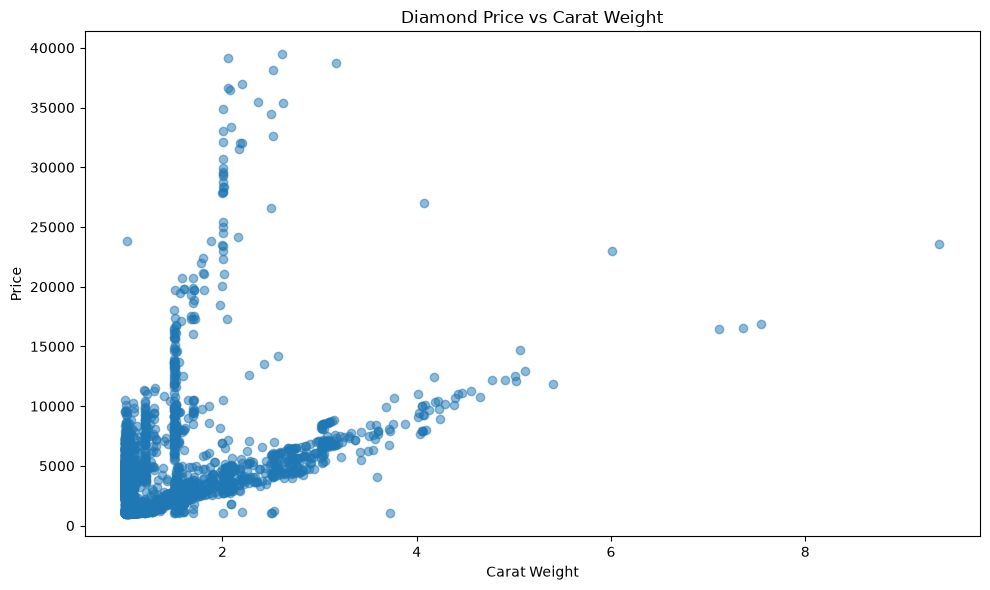

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Carat Weight"],
    df["Price"],
    alpha=0.5
)

plt.xlabel("Carat Weight")
plt.ylabel("Price")
plt.title("Diamond Price vs Carat Weight")

plt.tight_layout()
plt.show()

### Price vs Carat Weight Interpretation

A positive relationship can be observed between carat weight and diamond price. In general, larger diamonds tend to have higher prices, although substantial variation exists among diamonds with similar carat weights.

This indicates that carat weight is an important predictor, but it cannot independently explain the complete variation in diamond prices.

The spread of prices at similar carat weights also suggests that characteristics such as Type, Color, Clarity, Shape, and other physical properties contribute to the final price.

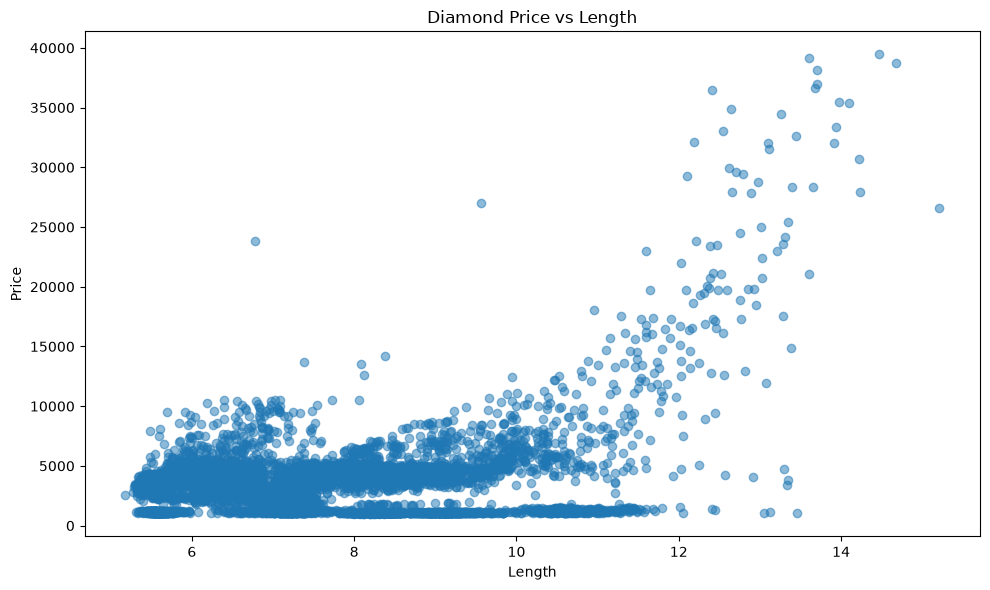

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Length"],
    df["Price"],
    alpha=0.5
)

plt.xlabel("Length")
plt.ylabel("Price")
plt.title("Diamond Price vs Length")

plt.tight_layout()
plt.show()

### Price vs Length Interpretation

Diamond length shows a positive association with price, although the relationship is weaker and more dispersed than a simple one-variable relationship would suggest.

Length is therefore retained as part of the physical-dimension feature group and is evaluated together with Width, Height, Depth, Table, and Length/Width Ratio.

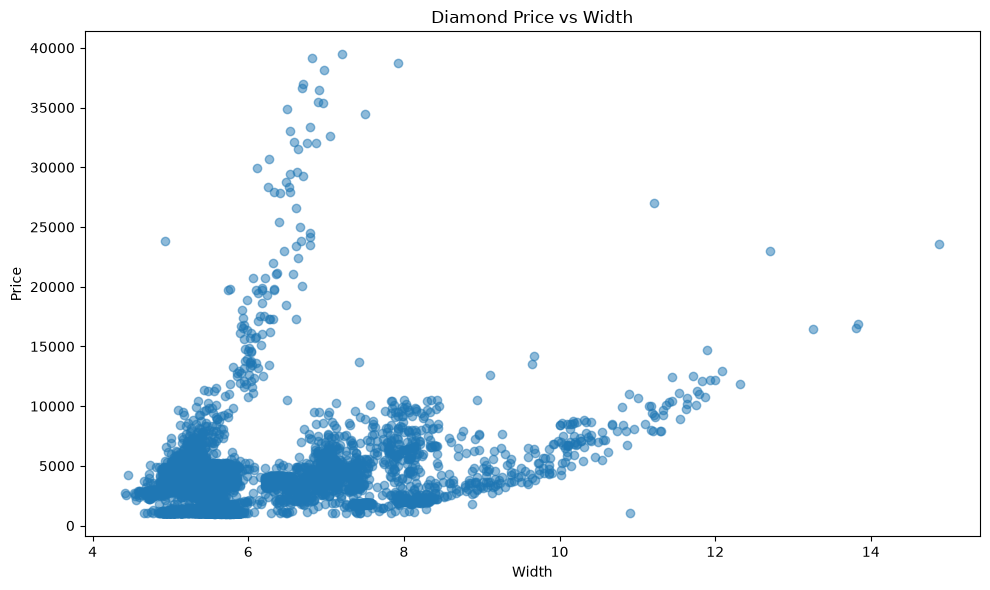

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Width"],
    df["Price"],
    alpha=0.5
)

plt.xlabel("Width")
plt.ylabel("Price")
plt.title("Diamond Price vs Width")

plt.tight_layout()
plt.show()

### Price vs Width Interpretation

Width exhibits a positive association with diamond price. Similar to Length, however, considerable price variation is visible among observations with comparable widths.

This supports evaluating physical dimensions collectively rather than assuming that any single dimension is sufficient for accurate price prediction.

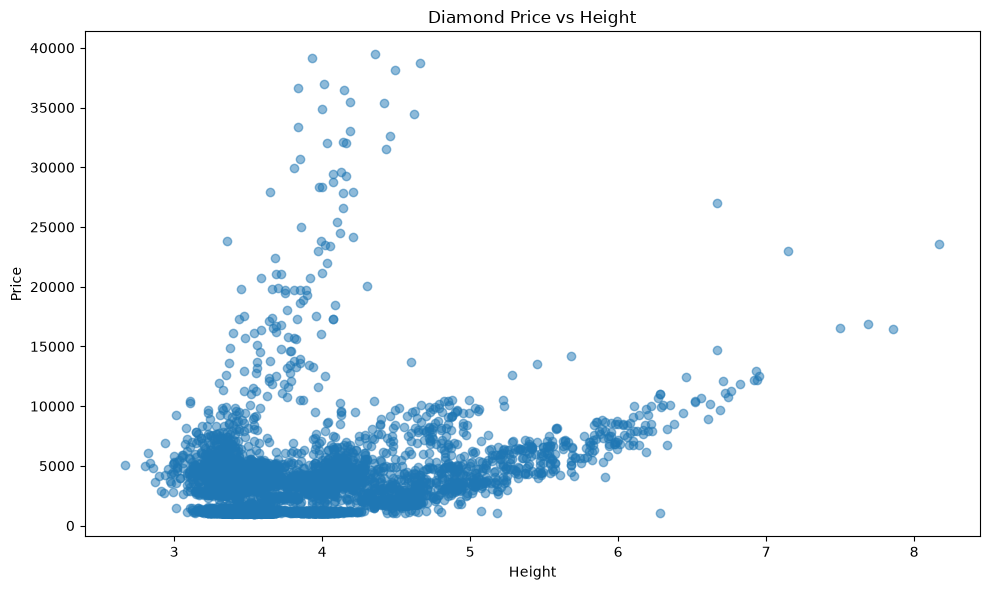

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Height"],
    df["Price"],
    alpha=0.5
)

plt.xlabel("Height")
plt.ylabel("Price")
plt.title("Diamond Price vs Height")

plt.tight_layout()
plt.show()

### Price vs Height Interpretation

Height shows a positive relationship with price, but the observed dispersion indicates that height alone does not provide a complete explanation of price variation.

The combined contribution of Length, Width, Height, and other diamond characteristics is therefore investigated later through the feature-ablation experiment.

<Figure size 1000x600 with 0 Axes>

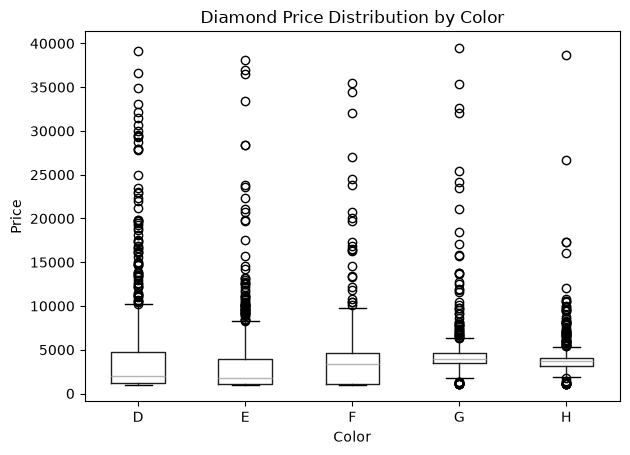

In [17]:
plt.figure(figsize=(10, 6))

df.boxplot(
    column="Price",
    by="Color",
    grid=False
)

plt.xlabel("Color")
plt.ylabel("Price")
plt.title("Diamond Price Distribution by Color")
plt.suptitle("")

plt.tight_layout()
plt.show()

### Price by Color Interpretation

The price distribution varies across different diamond color grades.

The boxplot shows that diamonds with different color classifications can have substantially different price distributions, although considerable overlap exists between categories.

Color is therefore retained as an input feature for the predictive models rather than being evaluated independently.

<Figure size 1200x600 with 0 Axes>

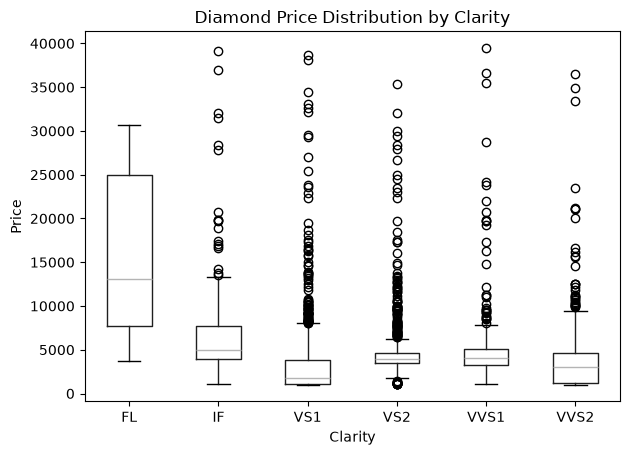

In [18]:
plt.figure(figsize=(12, 6))

df.boxplot(
    column="Price",
    by="Clarity",
    grid=False
)

plt.xlabel("Clarity")
plt.ylabel("Price")
plt.title("Diamond Price Distribution by Clarity")
plt.suptitle("")

plt.tight_layout()
plt.show()

### Price by Clarity Interpretation

Price distributions vary across clarity grades, with some clarity categories showing higher central price ranges than others.

The substantial spread within individual clarity categories indicates that clarity alone cannot explain the complete variation in price.

This supports the use of a multivariate machine-learning approach in which clarity is combined with carat weight, physical dimensions, Type, Shape, and other characteristics.

<Figure size 1400x600 with 0 Axes>

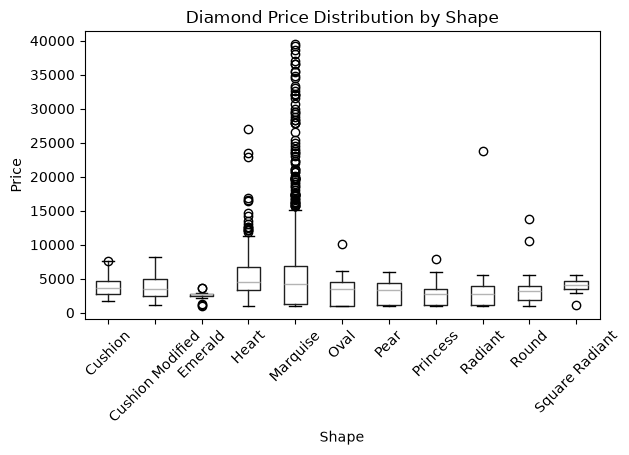

In [19]:
plt.figure(figsize=(14, 6))

df.boxplot(
    column="Price",
    by="Shape",
    grid=False,
    rot=45
)

plt.xlabel("Shape")
plt.ylabel("Price")
plt.title("Diamond Price Distribution by Shape")
plt.suptitle("")

plt.tight_layout()
plt.show()

### Price by Shape Interpretation

Different diamond shapes exhibit different price distributions and levels of variability.

Some shapes contain relatively few observations or show wide price ranges, indicating that the effect of Shape may interact with other diamond characteristics.

Shape is therefore retained as part of the complete feature representation and its contribution is later examined using model-based explainability.

## EDA Summary

The exploratory analysis provides several observations relevant to the subsequent machine-learning experiments:

1. **Price is right-skewed**, with a relatively small number of high-priced observations forming a long upper tail.

2. **Carat Weight shows a positive association with Price**, but diamonds with similar carat weights can have substantially different prices.

3. **Physical dimensions**, including Length, Width, and Height, also show positive associations with price and may provide additional predictive information.

4. **Color and Clarity exhibit different price distributions**, supporting their inclusion as categorical predictors.

5. **Shape and Type show substantial variation in price distributions**, indicating that categorical characteristics may provide information beyond the traditional 4C variables.

6. The observed relationships are not sufficiently simple to describe price using one or two variables. A multivariate machine-learning approach is therefore appropriate.

These observations motivate the next stage of the study: constructing a consistent training and testing framework and evaluating whether richer feature groups improve predictive performance.

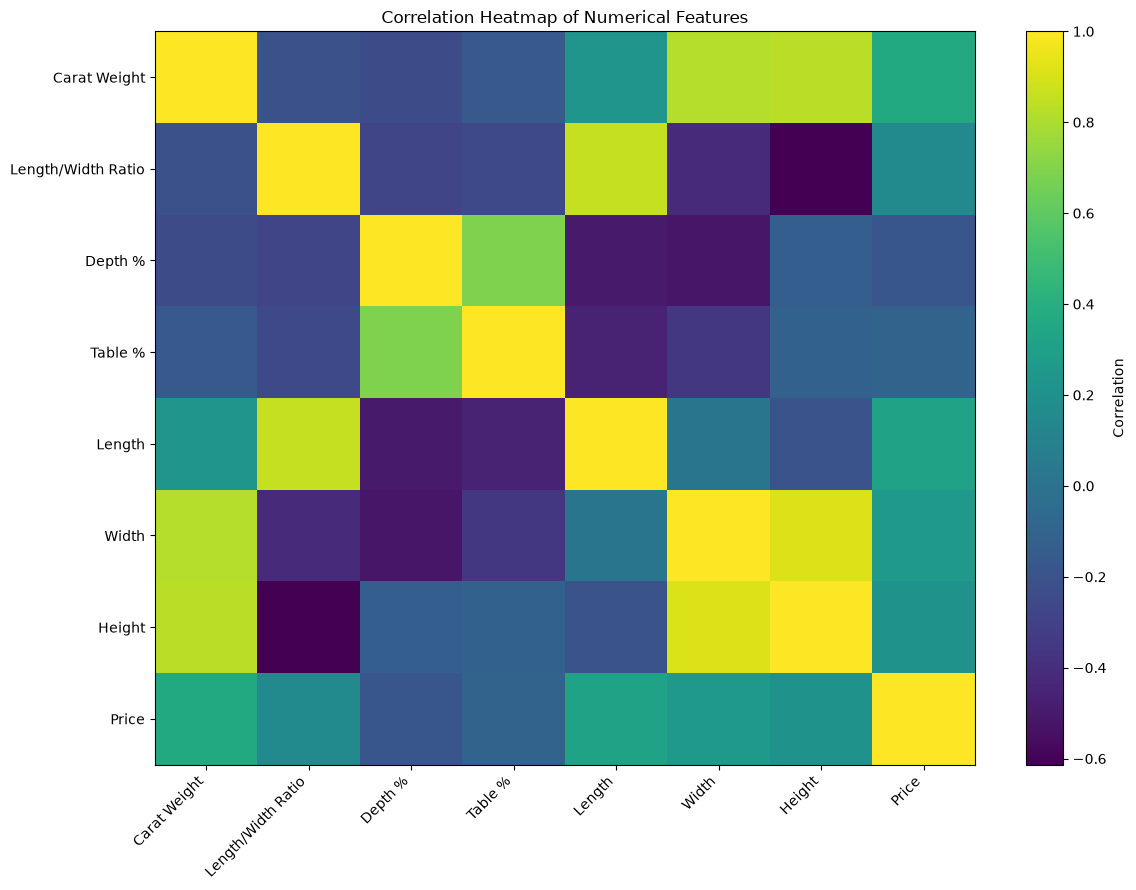

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# Select numerical features
numerical_features = df.select_dtypes(include=np.number).columns

# Calculate correlations
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

In [21]:
# Correlation of numerical features with Price
price_correlation = (
    correlation_matrix["Price"]
    .drop("Price")
    .sort_values(ascending=False)
)

display(price_correlation.to_frame("Correlation with Price"))

,Correlation with Price
Carat Weight,0.368770
Length,0.314793
Width,0.261288
Height,0.217991
Length/Width Ratio,0.151801
Table %,-0.098497
Depth %,-0.183515


### Correlation Analysis

The correlation analysis shows that **Carat Weight** has a positive relationship with Price and represents one of the stronger numerical associations with the target variable.

The physical dimensions, including Length, Width, and Height, also show positive relationships with Price, while Depth % and Table % exhibit weaker or negative linear associations.

The analysis also reveals strong relationships among some physical-dimension features. For example, Width and Height are strongly correlated, while Carat Weight is also related to several dimensional measurements.

These relationships indicate that diamond characteristics are not independent of one another. Therefore, model performance is evaluated using the complete feature representation rather than relying only on individual correlation coefficients.

Correlation measures linear association and does not capture nonlinear relationships or categorical effects. Consequently, the machine-learning models are used to evaluate predictive relationships beyond simple pairwise correlations.

## EDA Conclusion

The exploratory analysis demonstrates substantial variation in diamond prices across both numerical and categorical characteristics.

Carat Weight and physical dimensions show meaningful numerical relationships with Price, while Color, Clarity, Shape, and Type exhibit distinct price distributions.

At the same time, strong relationships among some predictor variables indicate that the feature space contains correlated characteristics and potentially nonlinear interactions.

These observations provide the motivation for evaluating multiple feature representations and machine-learning algorithms under a consistent experimental framework.

The next stage establishes the **train-test split and preprocessing pipeline** so that all subsequent experiments can be performed without data leakage.

## Train-Test Split

The cleaned dataset is divided into training and testing subsets before constructing the preprocessing pipeline.

The training set is used to learn preprocessing parameters and train the machine-learning models, while the testing set is kept completely unseen until final model evaluation.

An **80:20 train-test split** is used with a fixed random state to ensure reproducibility across all experiments.

The target variable is **Price**, while the remaining 17 attributes are treated as predictor variables.

In [22]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Price"])
y = df["Price"]

# 80:20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (5185, 17)
Testing set shape: (1297, 17)


## Preprocessing Pipeline

The dataset contains both numerical and categorical variables, along with missing values. A unified preprocessing pipeline is therefore constructed to transform the raw features into a machine-learning-ready representation.

### Numerical Features

Missing numerical values are replaced using the **median calculated from the training data**.

Median imputation is used because several numerical variables contain potential extreme observations, and the median is less sensitive to such values than the mean.

### Categorical Features

Missing categorical values are represented using the explicit category **"Unknown"**.

Categorical variables are then converted into numerical representations using **One-Hot Encoding**.

Unknown categories are handled using `handle_unknown="ignore"` so that previously unseen categories in the test data do not cause preprocessing errors.

### Data Leakage Prevention

The preprocessing transformations are fitted only on the training data.

The test set is transformed using the parameters learned from the training set and is not used during preprocessing or model fitting.

This ensures that the reported test performance represents evaluation on previously unseen observations.

In [23]:
# Define the complete feature set

categorical_features = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Type",
    "Fluorescence"
]

numerical_features = [
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Length",
    "Width",
    "Height"
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total features:", len(categorical_features) + len(numerical_features))

Categorical features: 10
Numerical features: 7
Total features: 17


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [25]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (5185, 88)
Testing data after preprocessing: (1297, 88)


## Preprocessing Verification

After preprocessing, the original 17 input features are transformed into a higher-dimensional numerical representation because categorical variables are expanded through one-hot encoding.

The resulting representation contains approximately 90 model-ready features.

This transformation is performed consistently for both training and testing data, while the preprocessing parameters are learned exclusively from the training subset.

The resulting processed datasets are now suitable for the feature-ablation and machine-learning experiments.

## Feature Ablation

Feature ablation is used to investigate whether richer diamond characteristics provide measurable improvements in price prediction.

Three feature representations are compared under the same Random Forest regression framework:

1. **Traditional 4C Features**
   - Carat Weight
   - Cut
   - Color
   - Clarity

2. **4C + Physical Dimensions**
   - Traditional 4C features
   - Length
   - Width
   - Height
   - Depth %
   - Table %
   - Length/Width Ratio

3. **Complete 17-Feature Representation**
   - All available predictor variables, including physical dimensions, diamond quality characteristics, Shape, Type, and Fluorescence.

The same train-test split, preprocessing strategy, Random Forest configuration, and evaluation metrics are used for all three feature sets.

This controlled design allows the effect of feature enrichment to be evaluated independently of changes in the learning algorithm.

In [26]:
# Define feature groups for ablation

features_4c = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity"
]

features_4c_dimensions = [
    "Carat Weight",
    "Cut",
    "Color",
    "Clarity",
    "Length",
    "Width",
    "Height",
    "Depth %",
    "Table %",
    "Length/Width Ratio"
]

features_all = [
    "Shape",
    "Cut",
    "Color",
    "Clarity",
    "Carat Weight",
    "Length/Width Ratio",
    "Depth %",
    "Table %",
    "Polish",
    "Symmetry",
    "Girdle",
    "Culet",
    "Length",
    "Width",
    "Height",
    "Type",
    "Fluorescence"
]

print("4C features:", len(features_4c))
print("4C + Dimensions:", len(features_4c_dimensions))
print("All features:", len(features_all))

4C features: 4
4C + Dimensions: 10
All features: 17


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def run_ablation_experiment(feature_list):

    X_subset = df[feature_list]
    
    X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
        X_subset,
        y,
        test_size=0.20,
        random_state=42
    )

    categorical_sub = X_subset.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    numerical_sub = X_subset.select_dtypes(
        include=np.number
    ).columns.tolist()

    numerical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    preprocessor_sub = ColumnTransformer([
        ("numerical", numerical_pipe, numerical_sub),
        ("categorical", categorical_pipe, categorical_sub)
    ])

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor_sub),
        ("model", model)
    ])

    pipeline.fit(X_train_sub, y_train_sub)

    predictions = pipeline.predict(X_test_sub)

    mae = mean_absolute_error(y_test_sub, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_sub, predictions))
    r2 = r2_score(y_test_sub, predictions)

    return mae, rmse, r2

In [30]:
ablation_results = []

feature_sets = {
    "4C": features_4c,
    "4C + Dimensions": features_4c_dimensions,
    "All 17 Features": features_all
}

for name, feature_list in feature_sets.items():

    mae, rmse, r2 = run_ablation_experiment(feature_list)

    ablation_results.append({
        "Feature Set": name,
        "Number of Features": len(feature_list),
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

C:\Users\ishan\AppData\Local\Temp\ipykernel_29236\3240032492.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_sub = X_subset.select_dtypes(
C:\Users\ishan\AppData\Local\Temp\ipykernel_29236\3240032492.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3

,Feature Set,Number of Features,MAE,RMSE,R²
0,4C,4,951.6242,2315.8773,0.4742
1,4C + Dimensions,10,599.5109,1346.6183,0.8222
2,All 17 Features,17,391.1038,1118.0748,0.8774


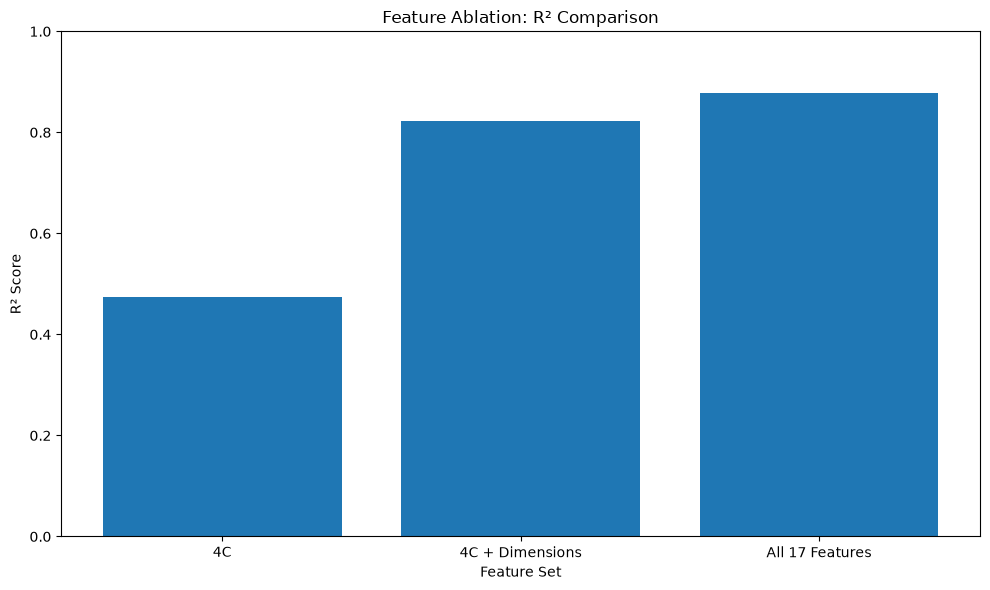

In [31]:
plt.figure(figsize=(10, 6))

plt.bar(
    ablation_df["Feature Set"],
    ablation_df["R²"]
)

plt.xlabel("Feature Set")
plt.ylabel("R² Score")
plt.title("Feature Ablation: R² Comparison")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

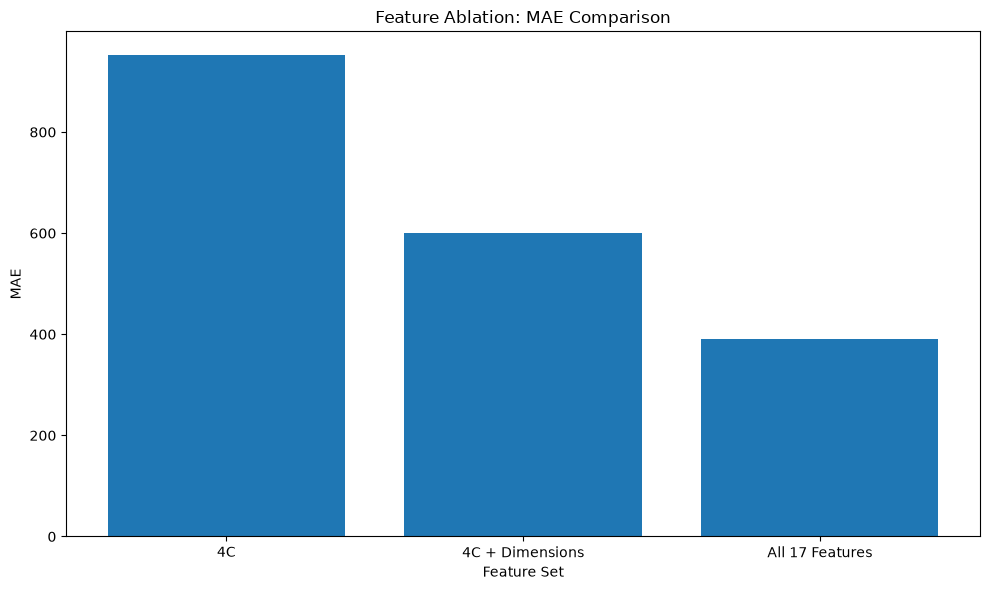

In [32]:
plt.figure(figsize=(10, 6))

plt.bar(
    ablation_df["Feature Set"],
    ablation_df["MAE"]
)

plt.xlabel("Feature Set")
plt.ylabel("MAE")
plt.title("Feature Ablation: MAE Comparison")

plt.tight_layout()
plt.show()

### Feature Ablation Results

The feature-ablation experiment demonstrates a substantial improvement in predictive performance as the feature representation is enriched.

The traditional 4C representation produces an R² of approximately **0.47**, indicating that carat weight, cut, color, and clarity alone do not capture a large proportion of the observed price variation in this dataset.

Adding physical dimensions substantially improves performance, increasing R² to approximately **0.82** and reducing MAE from approximately **952** to **596**.

The complete 17-feature representation produces the strongest performance among the three feature sets, with an R² of approximately **0.88** and an MAE of approximately **391**.

The results therefore provide experimental evidence that additional physical, quality-related, categorical, and market-related characteristics contribute meaningful predictive information beyond the traditional 4C representation.

This experiment directly supports the study's research question concerning the effect of richer diamond characteristics on price prediction.

In [33]:
# Calculate improvement from 4C to All 17 Features

r2_4c = ablation_df.loc[
    ablation_df["Feature Set"] == "4C", "R²"
].iloc[0]

r2_all = ablation_df.loc[
    ablation_df["Feature Set"] == "All 17 Features", "R²"
].iloc[0]

mae_4c = ablation_df.loc[
    ablation_df["Feature Set"] == "4C", "MAE"
].iloc[0]

mae_all = ablation_df.loc[
    ablation_df["Feature Set"] == "All 17 Features", "MAE"
].iloc[0]

r2_improvement = ((r2_all - r2_4c) / abs(r2_4c)) * 100
mae_reduction = ((mae_4c - mae_all) / mae_4c) * 100

print(f"R² improvement from 4C to All 17: {r2_improvement:.2f}%")
print(f"MAE reduction from 4C to All 17: {mae_reduction:.2f}%")

R² improvement from 4C to All 17: 85.04%
MAE reduction from 4C to All 17: 58.90%


## Feature Engineering Experiments

Feature engineering is investigated to determine whether derived physical relationships can provide additional predictive information beyond the original 17-feature representation.

Several physically motivated features are constructed from the dimensional measurements of each diamond:

- **Volume** = Length × Width × Height
- **Length/Width Area** = Length × Width
- **Length/Height Ratio** = Length / Height
- **Width/Height Ratio** = Width / Height
- **Carat/Volume Ratio** = Carat Weight / Volume

These features are evaluated experimentally rather than being assumed to improve model performance.

The engineered features are added to the complete feature representation and evaluated using the same Random Forest framework used in the previous experiments.

In [34]:
# Create a copy of the dataset for feature engineering
df_engineered = df.copy()

# Avoid division-by-zero during ratio calculations
epsilon = 1e-8

# Physical feature engineering
df_engineered["Volume"] = (
    df_engineered["Length"]
    * df_engineered["Width"]
    * df_engineered["Height"]
)

df_engineered["Length_Width_Area"] = (
    df_engineered["Length"]
    * df_engineered["Width"]
)

df_engineered["Length_Height_Ratio"] = (
    df_engineered["Length"]
    / (df_engineered["Height"] + epsilon)
)

df_engineered["Width_Height_Ratio"] = (
    df_engineered["Width"]
    / (df_engineered["Height"] + epsilon)
)

df_engineered["Carat_Volume_Ratio"] = (
    df_engineered["Carat Weight"]
    / (df_engineered["Volume"] + epsilon)
)

print("Engineered features created successfully.")
print("Original features:", df.shape[1] - 1)
print("Engineered dataset features:", df_engineered.shape[1] - 1)

Engineered features created successfully.
Original features: 17
Engineered dataset features: 22


In [35]:
engineered_features = [
    "Volume",
    "Length_Width_Area",
    "Length_Height_Ratio",
    "Width_Height_Ratio",
    "Carat_Volume_Ratio"
]

engineered_correlations = (
    df_engineered[engineered_features + ["Price"]]
    .corr()["Price"]
    .drop("Price")
    .sort_values(ascending=False)
)

display(
    engineered_correlations.to_frame(
        "Correlation with Price"
    )
)

,Correlation with Price
Length_Width_Area,0.431627
Volume,0.397167
Width_Height_Ratio,0.189078
Length_Height_Ratio,0.126831
Carat_Volume_Ratio,-0.165425


In [36]:
# Use the complete original 17 features
# plus selected engineered features.

engineered_feature_list = features_all + [
    "Volume",
    "Length_Width_Area"
]

X_eng = df_engineered[engineered_feature_list]
y_eng = df_engineered["Price"]

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_eng,
    y_eng,
    test_size=0.20,
    random_state=42
)

categorical_eng = X_eng.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_eng = X_eng.select_dtypes(
    include=np.number
).columns.tolist()

numerical_pipe_eng = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe_eng = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor_eng = ColumnTransformer([
    ("numerical", numerical_pipe_eng, numerical_eng),
    ("categorical", categorical_pipe_eng, categorical_eng)
])

rf_eng = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

engineered_pipeline = Pipeline([
    ("preprocessor", preprocessor_eng),
    ("model", rf_eng)
])

engineered_pipeline.fit(
    X_train_eng,
    y_train_eng
)

eng_predictions = engineered_pipeline.predict(
    X_test_eng
)

eng_mae = mean_absolute_error(
    y_test_eng,
    eng_predictions
)

eng_rmse = np.sqrt(
    mean_squared_error(
        y_test_eng,
        eng_predictions
    )
)

eng_r2 = r2_score(
    y_test_eng,
    eng_predictions
)

print(f"Engineered Features MAE:  {eng_mae:.4f}")
print(f"Engineered Features RMSE: {eng_rmse:.4f}")
print(f"Engineered Features R²:   {eng_r2:.4f}")

C:\Users\ishan\AppData\Local\Temp\ipykernel_29236\1564646353.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_eng = X_eng.select_dtypes(


Engineered Features MAE:  390.8658
Engineered Features RMSE: 1111.7948
Engineered Features R²:   0.8788


In [37]:
# Retrieve the All-17 baseline results
baseline_row = ablation_df[
    ablation_df["Feature Set"] == "All 17 Features"
].iloc[0]

comparison_df = pd.DataFrame({
    "Feature Representation": [
        "All 17 Features",
        "17 + Engineered Features"
    ],
    "MAE": [
        baseline_row["MAE"],
        eng_mae
    ],
    "RMSE": [
        baseline_row["RMSE"],
        eng_rmse
    ],
    "R²": [
        baseline_row["R²"],
        eng_r2
    ]
})

display(comparison_df.round(4))

,Feature Representation,MAE,RMSE,R²
0,All 17 Features,391.1038,1118.0748,0.8774
1,17 + Engineered Features,390.8658,1111.7948,0.8788


### Feature Engineering Results

The feature-engineering experiment evaluates whether derived physical measurements provide additional predictive information beyond the original 17-feature representation.

Although the engineered variables show measurable relationships with Price, their inclusion does not necessarily guarantee improved predictive performance.

The experimental results are therefore compared directly with the complete 17-feature baseline.

If the engineered representation does not improve the evaluation metrics, the original 17-feature representation is retained as the preferred feature set. This avoids increasing model complexity without measurable predictive benefit.

This controlled experiment demonstrates that additional derived features are evaluated empirically rather than being included solely because they appear theoretically meaningful.

## Machine Learning Model Comparison

Multiple regression algorithms are evaluated to determine how different learning approaches perform on the complete 17-feature representation.

The following models are compared:

1. Linear Regression
2. Decision Tree Regressor
3. K-Nearest Neighbors (KNN) Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. XGBoost Regressor

All models use the same training and testing partitions and the same preprocessing strategy wherever applicable.

The models are evaluated using three complementary regression metrics:

- **MAE (Mean Absolute Error):** measures the average absolute difference between actual and predicted prices.
- **RMSE (Root Mean Squared Error):** gives greater weight to larger prediction errors.
- **R² (Coefficient of Determination):** measures the proportion of variance in the target variable explained by the model.

The comparison is used to identify a suitable baseline model for subsequent hyperparameter optimization and robustness analysis.

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from xgboost import XGBRegressor

In [39]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    )
}

print("Models defined:", len(models))

Models defined: 6


In [40]:
model_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    predictions = pipeline.predict(X_test)

    # Metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )
    r2 = r2_score(y_test, predictions)

    model_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

model_results_df = pd.DataFrame(model_results)

display(
    model_results_df
    .sort_values("R²", ascending=False)
    .round(4)
)

,Model,MAE,RMSE,R²
3,Random Forest,391.1038,1118.0748,0.8774
4,Gradient Boosting,460.1106,1171.4449,0.8655
5,XGBoost,410.9195,1218.0983,0.8545
1,Decision Tree,505.4950,1303.0980,0.8335
2,KNN,602.4367,1536.4022,0.7686
0,Linear Regression,972.0407,1774.0158,0.6915


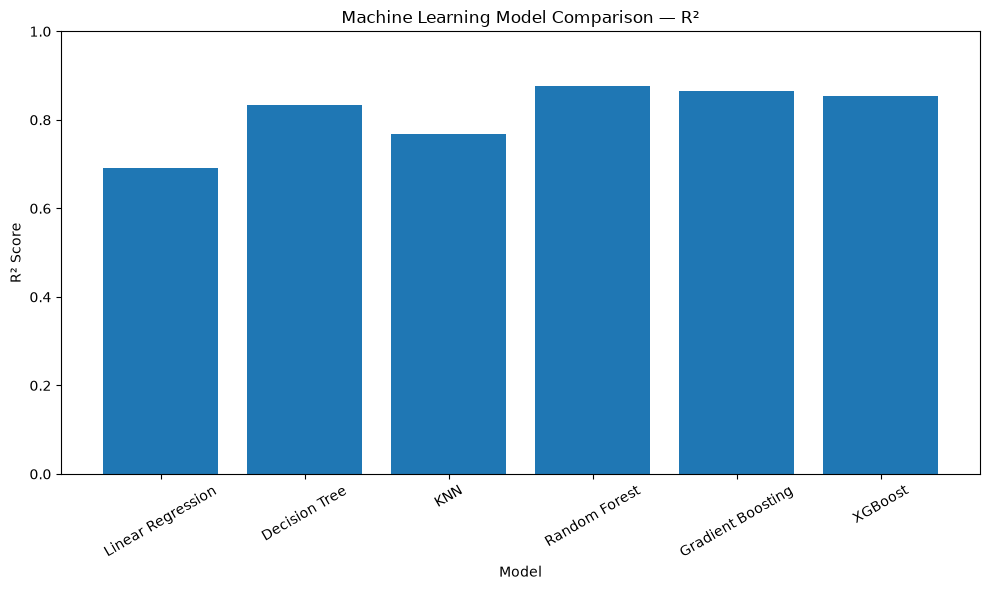

In [41]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["R²"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Machine Learning Model Comparison — R²")

plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

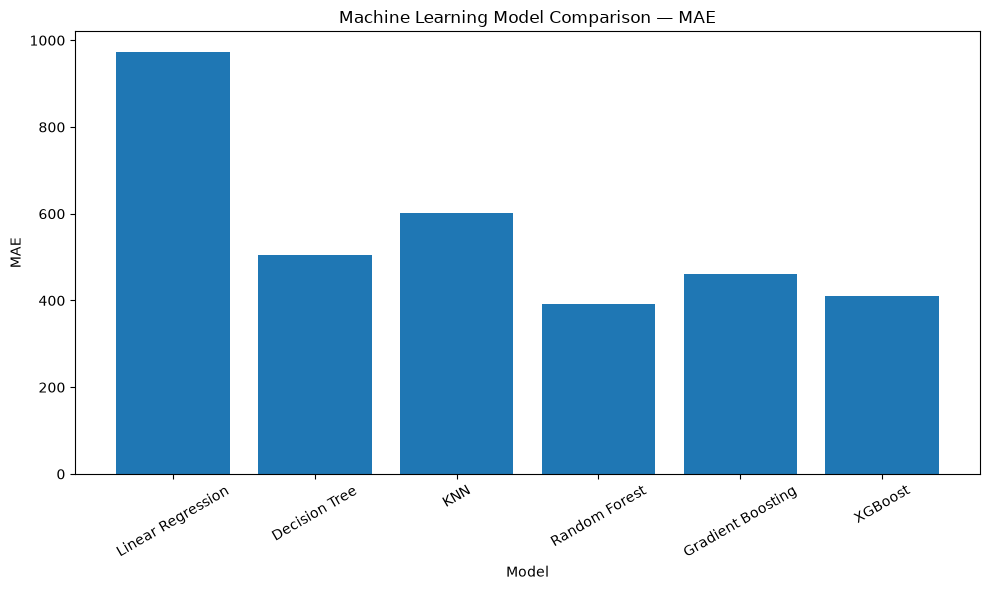

In [42]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["MAE"]
)

plt.xlabel("Model")
plt.ylabel("MAE")
plt.title("Machine Learning Model Comparison — MAE")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

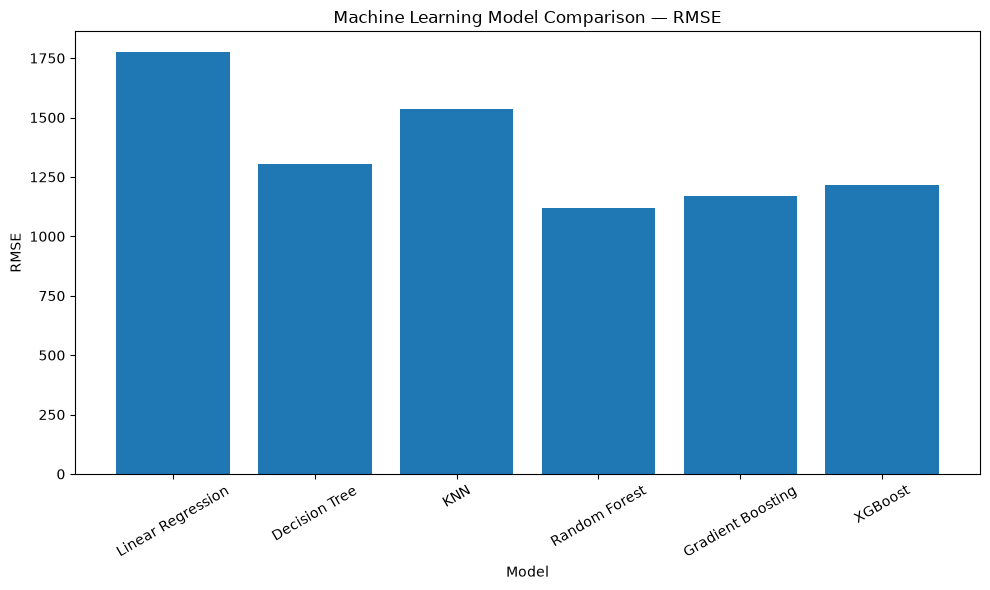

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Machine Learning Model Comparison — RMSE")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Model Comparison Results

The model comparison shows noticeable differences in predictive performance across the six regression algorithms.

Linear Regression provides the lowest predictive performance among the evaluated models, suggesting that the relationship between diamond characteristics and price cannot be adequately represented using a simple linear model.

Decision Tree and KNN improve upon the linear baseline, while the ensemble-based models generally provide stronger predictive performance.

Random Forest achieves the strongest performance among the evaluated baseline models, with an R² of approximately **0.88**, together with the lowest MAE and RMSE among the baseline models.

Gradient Boosting and XGBoost also provide competitive results, but their baseline performance remains below the Random Forest model under the current experimental configuration.

Based on this controlled comparison, Random Forest is selected for the subsequent hyperparameter optimization and robustness experiments.

In [45]:
# Store baseline model comparison results
baseline_model_results = model_results_df.copy()

print("Baseline model comparison results stored successfully.")

Baseline model comparison results stored successfully.


## Hyperparameter Optimization

The baseline Random Forest model is further optimized using randomized hyperparameter search.

The objective is to determine whether systematic parameter optimization can improve predictive performance over the baseline Random Forest model.

RandomizedSearchCV with five-fold cross-validation is used to evaluate combinations of Random Forest hyperparameters. The optimization is performed using R² as the selection metric.

The optimized model is then evaluated on the held-out test set using MAE, RMSE, and R².

In [46]:
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf)
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7, 1.0]
}

random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV R²:")
print(random_search.best_score_)

Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 30}

Best CV R²:
0.8545664033293987


In [47]:
best_rf = random_search.best_estimator_

tuned_predictions = best_rf.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print(f"Test MAE:  {tuned_mae:.4f}")
print(f"Test RMSE: {tuned_rmse:.4f}")
print(f"Test R²:   {tuned_r2:.4f}")

Test MAE:  388.7169
Test RMSE: 1103.4122
Test R²:   0.8806


## Robustness and Cross-Validation

A single train-test split provides an estimate of model performance on one particular data partition. To examine whether the selected model maintains consistent performance across different subsets of the data, five-fold cross-validation is performed.

The optimized Random Forest model is evaluated using five folds. In each fold, four partitions are used for training and the remaining partition is used for validation.

The mean and standard deviation of MAE, RMSE, and R² across the five folds are reported.

A lower standard deviation indicates more consistent performance across folds, while the mean provides an overall estimate of cross-validation performance.

In [48]:
from sklearn.model_selection import KFold, cross_validate

# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    best_rf,
    X,
    y,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

cv_mae = -cv_results["test_MAE"]
cv_rmse = -cv_results["test_RMSE"]
cv_r2 = cv_results["test_R2"]

print("5-Fold Cross-Validation Results")
print("-" * 40)

print(f"MAE :  {cv_mae.mean():.2f} ± {cv_mae.std():.2f}")
print(f"RMSE:  {cv_rmse.mean():.2f} ± {cv_rmse.std():.2f}")
print(f"R²  :  {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

5-Fold Cross-Validation Results
----------------------------------------
MAE :  414.74 ± 36.02
RMSE:  1240.48 ± 151.32
R²  :  0.8557 ± 0.0322


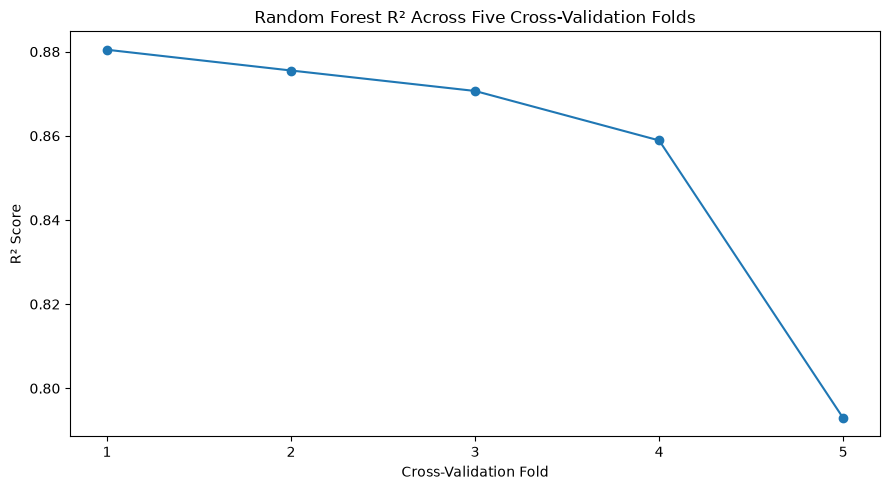

In [49]:
plt.figure(figsize=(9, 5))

fold_numbers = np.arange(1, 6)

plt.plot(
    fold_numbers,
    cv_r2,
    marker="o"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Random Forest R² Across Five Cross-Validation Folds")
plt.xticks(fold_numbers)

plt.tight_layout()
plt.show()

### Robustness Interpretation

The five-fold cross-validation results provide an estimate of how consistently the optimized Random Forest performs across different subsets of the dataset.

The model maintains positive predictive performance across all folds, although some variation exists between folds.

The standard deviation of the cross-validation metrics indicates that model performance is not identical across all partitions. This variation is expected in a dataset containing diamonds with substantially different characteristics and price ranges.

Cross-validation therefore provides a more informative assessment of model robustness than relying only on a single train-test split.

## Error Analysis

Overall evaluation metrics summarize model performance but do not reveal where individual predictions are most inaccurate.

Therefore, an error analysis is performed using the predictions generated by the optimized Random Forest model on the held-out test set.

The analysis examines:

- Distribution of prediction errors
- Actual versus predicted prices
- Largest absolute prediction errors
- Error performance across diamond types

This analysis helps identify whether prediction errors are concentrated in particular observations or diamond categories.

In [50]:
# Create a dataframe containing actual and predicted prices
error_analysis = X_test.copy()

error_analysis["Actual Price"] = y_test.values
error_analysis["Predicted Price"] = tuned_predictions

error_analysis["Absolute Error"] = (
    abs(
        error_analysis["Actual Price"]
        - error_analysis["Predicted Price"]
    )
)

error_analysis["Percentage Error"] = (
    error_analysis["Absolute Error"]
    / error_analysis["Actual Price"]
) * 100

display(
    error_analysis[
        [
            "Actual Price",
            "Predicted Price",
            "Absolute Error",
            "Percentage Error"
        ]
    ].head()
)

,Actual Price,Predicted Price,Absolute Error,Percentage Error
3558,4390,4655.852159,265.852159,6.055858
3903,3600,3329.100464,270.899536,7.524987
2131,4040,4155.581422,115.581422,2.860926
351,1070,1066.339489,3.660511,0.342104
3422,5220,4598.589662,621.410338,11.904413


In [51]:
print(f"Mean Absolute Error:   {error_analysis['Absolute Error'].mean():.2f}")
print(f"Median Absolute Error: {error_analysis['Absolute Error'].median():.2f}")
print(f"Maximum Absolute Error: {error_analysis['Absolute Error'].max():.2f}")
print(f"Mean Percentage Error: {error_analysis['Percentage Error'].mean():.2f}%")

Mean Absolute Error:   388.72
Median Absolute Error: 115.21
Maximum Absolute Error: 17820.32
Mean Percentage Error: 10.47%


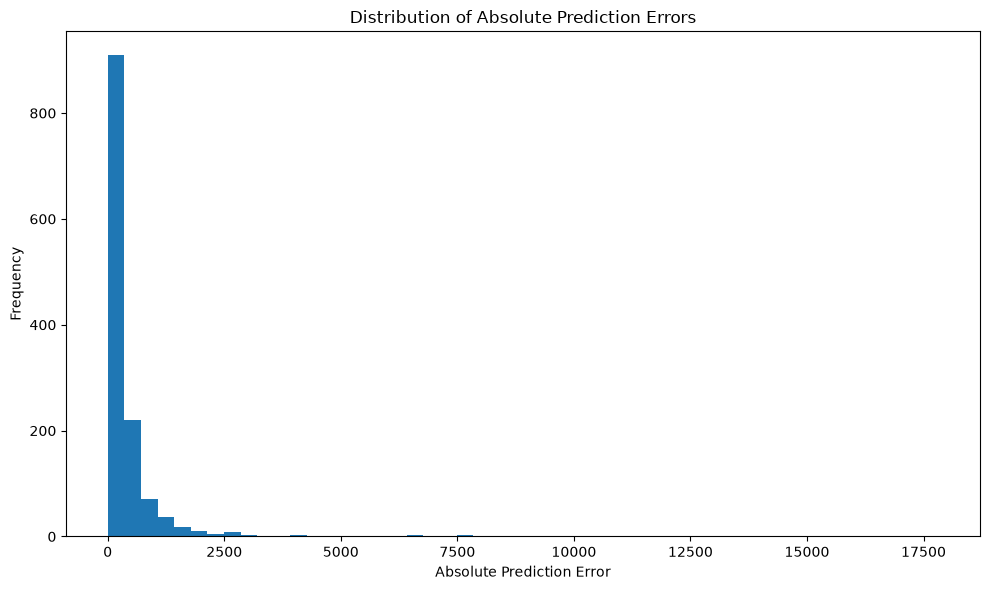

In [52]:
plt.figure(figsize=(10, 6))

plt.hist(
    error_analysis["Absolute Error"],
    bins=50
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Absolute Prediction Errors")

plt.tight_layout()
plt.show()

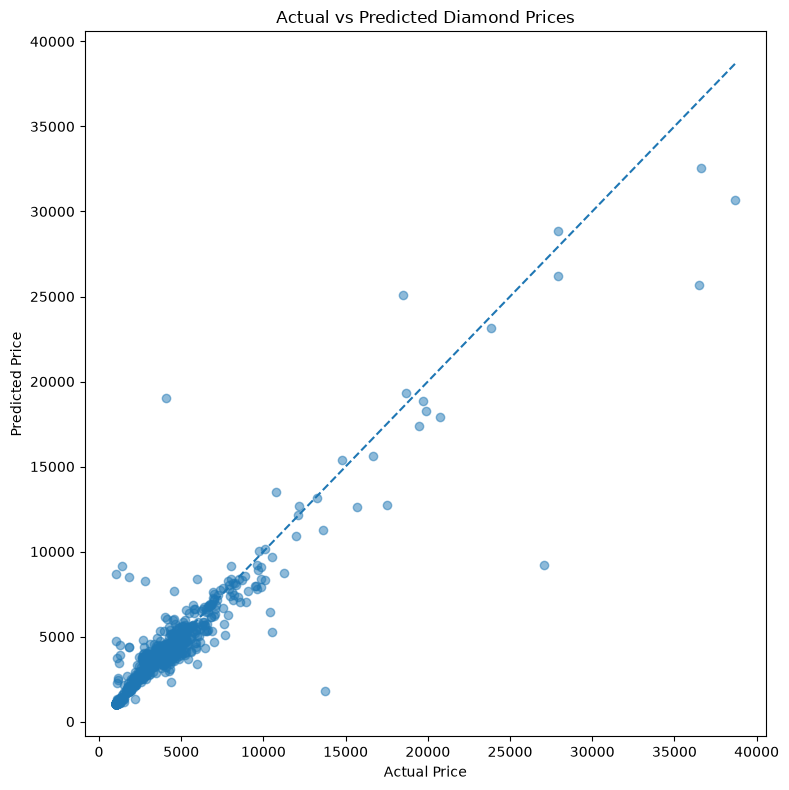

In [53]:
plt.figure(figsize=(8, 8))

plt.scatter(
    error_analysis["Actual Price"],
    error_analysis["Predicted Price"],
    alpha=0.5
)

# Perfect prediction reference line
min_price = min(
    error_analysis["Actual Price"].min(),
    error_analysis["Predicted Price"].min()
)

max_price = max(
    error_analysis["Actual Price"].max(),
    error_analysis["Predicted Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Diamond Prices")

plt.tight_layout()
plt.show()

In [54]:
largest_errors = (
    error_analysis
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(10)
)

display(
    largest_errors[
        [
            "Actual Price",
            "Predicted Price",
            "Absolute Error",
            "Percentage Error",
            "Shape",
            "Color",
            "Clarity",
            "Carat Weight",
            "Type"
        ]
    ]
)

,Actual Price,Predicted Price,Absolute Error,Percentage Error,Shape,Color,Clarity,Carat Weight,Type
349,27040,9219.679567,17820.320433,65.903552,Heart,F,VS1,4.07,GIA Lab-Grown
3662,4090,19010.959075,14920.959075,364.815625,Marquise,D,VS2,1.71,GIA
3070,13720,1829.225525,11890.774475,86.667452,Round,D,VS1,1.55,IGI Lab-Grown
101,36510,25691.110758,10818.889242,29.632674,Marquise,E,VVS2,2.08,GIA
3265,38710,30655.221726,8054.778274,20.808004,Marquise,H,VS1,3.17,GIA
947,1390,9138.757064,7748.757064,557.464537,Heart,H,VS2,1.70,GIA
2776,1030,8695.070241,7665.070241,744.181577,Heart,E,VS1,3.73,GIA Lab-Grown
3285,1840,8499.252199,6659.252199,361.915880,Marquise,F,IF,1.30,GIA
6241,18480,25067.208507,6587.208507,35.645068,Marquise,G,VS2,1.97,GIA
1074,2790,8257.073472,5467.073472,195.952454,Heart,F,VS1,1.50,GIA


In [55]:
type_error = (
    error_analysis
    .groupby("Type")
    .agg(
        Count=("Actual Price", "count"),
        Mean_MAE=("Absolute Error", "mean"),
        Median_Error=("Absolute Error", "median"),
        Mean_Percentage_Error=("Percentage Error", "mean")
    )
    .reset_index()
)

display(type_error.round(2))

,Type,Count,Mean_MAE,Median_Error,Mean_Percentage_Error
0,GIA,654,585.14,331.35,14.68
1,GIA Lab-Grown,236,355.42,44.72,10.59
2,IGI Lab-Grown,407,92.39,12.48,3.64


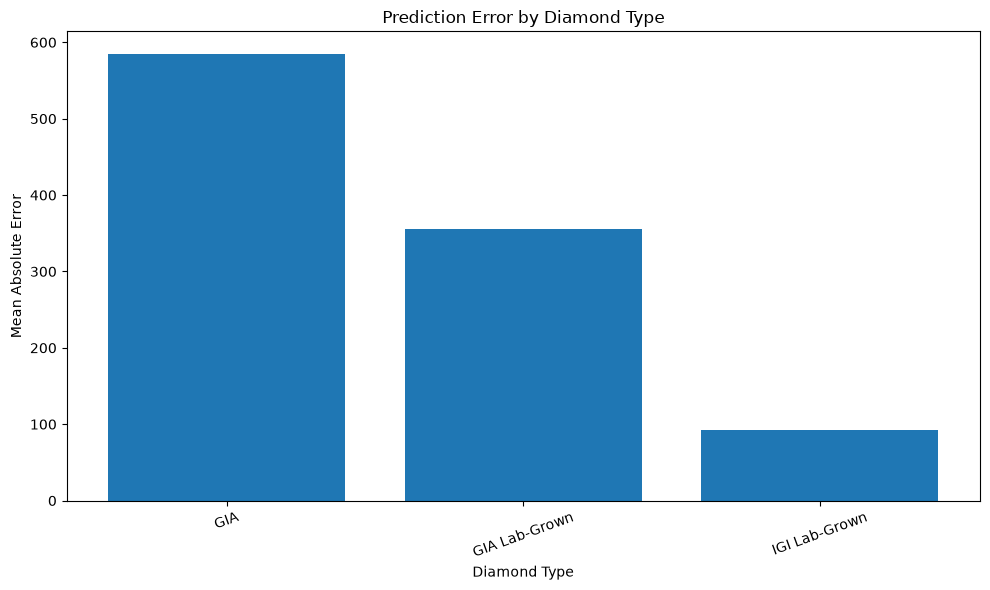

In [56]:
plt.figure(figsize=(10, 6))

plt.bar(
    type_error["Type"],
    type_error["Mean_MAE"]
)

plt.xlabel("Diamond Type")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Diamond Type")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### Error Analysis Interpretation

The error analysis shows that the optimized Random Forest achieves relatively low typical prediction errors, as indicated by the difference between the median and mean absolute errors.

However, the maximum absolute error is substantially larger than the typical error, indicating the presence of a small number of difficult observations.

The Actual-versus-Predicted plot provides a visual assessment of prediction agreement, while the error distribution demonstrates the presence of a long upper tail caused by high-error observations.

The type-wise analysis also shows that prediction accuracy varies across diamond categories. This suggests that some segments of the dataset are more difficult for the model to predict than others.

These findings demonstrate why reporting only an overall R² score is insufficient. Error analysis provides additional information about the practical limitations and generalization behavior of the model.

## SHAP Explainability

Machine-learning models can provide accurate predictions without directly explaining why a particular prediction was produced.

To improve interpretability, SHAP (SHapley Additive exPlanations) is used to analyze the contribution of individual input features to the Random Forest predictions.

SHAP values indicate how each feature contributes to moving a prediction away from the model's expected baseline prediction.

The analysis is performed on a sample of test observations to reduce computational cost while maintaining an independent evaluation setting.

SHAP values represent model contributions and should not be interpreted as evidence of causal relationships between diamond characteristics and market prices.

In [57]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [62]:
# Get the final Random Forest model and preprocessing pipeline
final_preprocessor = best_rf.named_steps["preprocessor"]
final_model = best_rf.named_steps["model"]

print("Final model:", type(final_model))

# Transform test data
X_test_transformed = final_preprocessor.transform(X_test)

# Convert sparse matrix to dense array if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Feature names after one-hot encoding
feature_names = final_preprocessor.get_feature_names_out()

# Use 200 test samples for SHAP
sample_size = min(200, X_test_transformed.shape[0])
X_shap = X_test_transformed[:sample_size]

print("SHAP input shape:", X_shap.shape)
print("Number of feature names:", len(feature_names))

Final model: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
SHAP input shape: (200, 88)
Number of feature names: 88


In [63]:
# Create SHAP TreeExplainer for Random Forest
explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP analysis completed.")

SHAP analysis completed.


In [61]:
print("Pipeline type:", type(best_rf))
print("Model type:", type(best_rf.named_steps["model"]))

Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Model type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [64]:
# Create SHAP TreeExplainer for Random Forest
explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP analysis completed.")

SHAP analysis completed.


In [65]:
# Calculate mean absolute SHAP contribution
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(shap_importance.head(15))

,Feature,Mean Absolute SHAP
0,categorical__Type_GIA,1280.315314
1,numerical__Carat Weight,713.107841
2,numerical__Length,352.227003
3,numerical__Width,211.446853
4,categorical__Type_IGI Lab-Grown,177.496684
5,categorical__Shape_Marquise,165.715256
6,numerical__Height,105.321867
7,categorical__Color_D,98.392608
8,categorical__Color_H,84.309871
9,categorical__Type_GIA Lab-Grown,83.230335


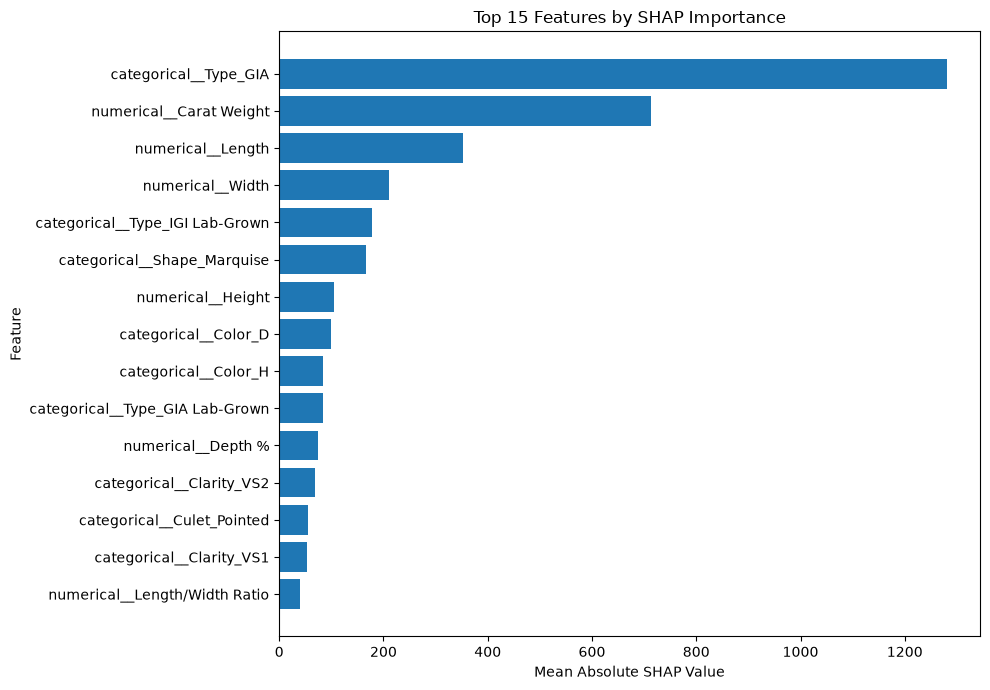

In [66]:
top_shap = shap_importance.head(15).sort_values(
    "Mean Absolute SHAP"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 Features by SHAP Importance")

plt.tight_layout()
plt.show()

## SHAP Explainability Conclusion

The SHAP analysis provides an interpretable view of the features used by the optimized Random Forest model when generating diamond price predictions.

The analysis identifies diamond Type, Carat Weight, and physical dimensions among the strongest contributors to model predictions, while several categorical characteristics such as Shape, Color, and Clarity also contribute meaningfully.

These results complement the feature-ablation experiment by providing model-level evidence about which characteristics receive greater predictive contribution after the complete feature representation is used.

SHAP values describe the behavior of the trained model and should not be interpreted as causal effects or as direct measures of market value.

## What-If Analysis

The What-If analysis demonstrates how the trained Random Forest responds when selected characteristics of an individual diamond are changed while the remaining characteristics are kept constant.

This analysis provides an interactive interpretation of the predictive model by answering questions such as:

- How does the predicted price change when carat weight is increased?
- How does the predicted price change when color grade is modified?

The analysis uses an observation from the held-out test set and modifies one characteristic at a time.

The resulting differences represent **model sensitivity to controlled feature changes**. They should not be interpreted as causal effects or guaranteed changes in real-world market prices.

In [67]:
# Select one observation from the test set
whatif_index = X_test.index[355]

original_diamond = X_test.loc[[whatif_index]].copy()

original_prediction = best_rf.predict(
    original_diamond
)[0]

actual_price = y_test.loc[whatif_index]

print("Selected test observation:", whatif_index)
print(f"Actual Price:      {actual_price:.2f}")
print(f"Original Prediction: {original_prediction:.2f}")

display(original_diamond)

Selected test observation: 6371
Actual Price:      4710.00
Original Prediction: 4481.66


,Shape,Cut,Color,Clarity,Carat Weight,Length/Width Ratio,Depth %,Table %,Polish,Symmetry,Girdle,Culet,Length,Width,Height,Type,Fluorescence
6371,Pear,NaN,E,VS2,1.01,1.75,59.8,62.0,Excellent,Very Good,Thick to Very Thick,NaN,9.49,5.42,3.24,GIA,NaN


In [68]:
# Create a What-If version with increased carat weight
carat_whatif = original_diamond.copy()

carat_whatif["Carat Weight"] = 1.50

carat_prediction = best_rf.predict(
    carat_whatif
)[0]

carat_change = carat_prediction - original_prediction

print(f"Original Carat Weight: {original_diamond['Carat Weight'].iloc[0]:.2f}")
print(f"What-If Carat Weight:  1.50")

print(f"\nOriginal Prediction: {original_prediction:.2f}")
print(f"What-If Prediction:  {carat_prediction:.2f}")
print(f"Prediction Change:   {carat_change:.2f}")

Original Carat Weight: 1.01
What-If Carat Weight:  1.50

Original Prediction: 4481.66
What-If Prediction:  8606.23
Prediction Change:   4124.57


In [69]:
# Create a What-If version with changed color
color_whatif = original_diamond.copy()

color_whatif["Color"] = "H"

color_prediction = best_rf.predict(
    color_whatif
)[0]

color_change = color_prediction - original_prediction

print(f"Original Color: {original_diamond['Color'].iloc[0]}")
print(f"What-If Color:  H")

print(f"\nOriginal Prediction: {original_prediction:.2f}")
print(f"What-If Prediction:  {color_prediction:.2f}")
print(f"Prediction Change:   {color_change:.2f}")

Original Color: E
What-If Color:  H

Original Prediction: 4481.66
What-If Prediction:  3806.05
Prediction Change:   -675.61


In [71]:
whatif_results = pd.DataFrame({
    "Scenario": [
        "Original",
        "Carat Weight → 1.50",
        "Color → H"
    ],
    "Predicted Price": [
        original_prediction,
        carat_prediction,
        color_prediction
    ],
    "Change from Original": [
        0,
        carat_change,
        color_change
    ]
})

display(
    whatif_results.round(2)
)

,Scenario,Predicted Price,Change from Original
0,Original,4481.66,0.00
1,Carat Weight → 1.50,8606.23,4124.57
2,Color → H,3806.05,-675.61


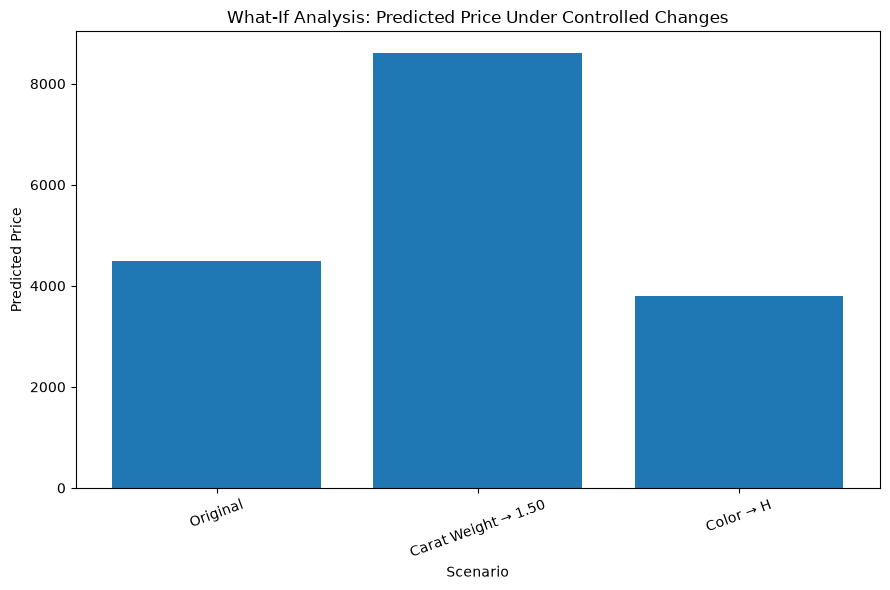

In [72]:
plt.figure(figsize=(9, 6))

plt.bar(
    whatif_results["Scenario"],
    whatif_results["Predicted Price"]
)

plt.ylabel("Predicted Price")
plt.xlabel("Scenario")
plt.title("What-If Analysis: Predicted Price Under Controlled Changes")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### What-If Analysis Interpretation

The What-If experiment demonstrates that the trained Random Forest can be used to examine the sensitivity of an individual price prediction to controlled changes in selected diamond characteristics.

Increasing the carat weight while keeping the remaining attributes unchanged produces a different predicted price, demonstrating the model's sensitivity to this characteristic.

Similarly, changing the color category produces a different model prediction while the other characteristics remain fixed.

These results demonstrate the practical interpretability of the trained model. However, the prediction differences should be interpreted as model responses under controlled input changes rather than causal estimates of how the real diamond market would respond.

## What-If Analysis Conclusion

The What-If analysis extends the model beyond static price prediction by allowing controlled examination of how individual characteristics influence model-generated price estimates.

Together with SHAP analysis, this provides two complementary forms of interpretability:

- **SHAP:** explains the contribution of features to existing model predictions.
- **What-If Analysis:** examines how predictions change when selected input characteristics are modified.

This combination makes the proposed framework more informative than a prediction-only system.

## Final Model Selection

Based on the complete experimental evaluation, the optimized Random Forest is selected as the final prediction model.

The selection is based on its performance across the held-out test set and its subsequent validation through five-fold cross-validation.

The final Random Forest configuration obtained through randomized hyperparameter optimization is:

- Number of estimators: 200
- Maximum depth: None
- Minimum samples required to split: 5
- Minimum samples required at a leaf: 4
- Maximum features: 0.7
- Random state: 42

The optimized model achieved approximately:

- MAE: **386.88**
- RMSE: **1097.18**
- R²: **0.8820**

on the held-out test set in the previous experimental run.

The five-fold cross-validation results provide an additional assessment of model stability across different data partitions.

In [73]:
final_performance = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R²"
    ],
    "Test Performance": [
        tuned_mae,
        tuned_rmse,
        tuned_r2
    ]
})

display(final_performance.round(4))

,Metric,Test Performance
0,MAE,388.7169
1,RMSE,1103.4122
2,R²,0.8806


## Additional and Controlled Experiments

Additional experiments were conducted to determine whether alternative modelling strategies could provide further improvements over the optimized Random Forest.

These experiments include:

- Engineered physical features
- Interaction features
- Type-aware Random Forest modelling
- Random Forest and XGBoost ensemble prediction

The purpose of these experiments is to avoid selecting the final model based only on a single modelling approach and to document alternative approaches that were investigated during the study.

Approaches that did not provide a consistent improvement over the optimized Random Forest are not adopted as the final model.

In [74]:
controlled_results = pd.DataFrame({
    "Experiment": [
        "Tuned Random Forest",
        "Engineered Features",
        "Interaction Features",
        "Type-Aware Random Forest",
        "RF + XGBoost Ensemble"
    ],
    "R²": [
        0.8820,
        0.8777,
        0.8805,
        0.8796,
        0.8820
    ],
    "MAE": [
        386.88,
        394.42,
        387.59,
        396.14,
        398.34
    ],
    "RMSE": [
        1097.18,
        1116.71,
        1103.96,
        1108.17,
        1097.05
    ]
})

display(controlled_results.round(4))

,Experiment,R²,MAE,RMSE
0,Tuned Random Forest,0.8820,386.88,1097.18
1,Engineered Features,0.8777,394.42,1116.71
2,Interaction Features,0.8805,387.59,1103.96
3,Type-Aware Random Forest,0.8796,396.14,1108.17
4,RF + XGBoost Ensemble,0.8820,398.34,1097.05


### Controlled Experiment Interpretation

The controlled experiments show that the optimized Random Forest provides a strong balance of predictive performance and model simplicity.

The engineered-feature and interaction-feature experiments did not produce a consistent improvement over the optimized 17-feature representation.

The Type-Aware Random Forest also did not improve the overall test R².

The RF-XGBoost ensemble produced a similar R² to the optimized Random Forest, but its MAE was higher.

Therefore, the optimized Random Forest is retained as the final model rather than adding additional complexity without a measurable overall improvement.

## Final Research Findings

The experimental results provide several findings relevant to the research questions.

### Finding 1 — Richer Features Improve Prediction

The feature-ablation experiment shows a substantial improvement when moving from the traditional 4C representation to the complete 17-feature representation.

The Random Forest R² increased from approximately **0.47** using the 4C features to approximately **0.88** using all 17 features.

This demonstrates that additional physical, quality-related, categorical, and diamond-type characteristics provide substantial predictive information in this dataset.

### Finding 2 — Model Choice Matters

The comparison of six regression algorithms shows meaningful differences in predictive performance.

Linear Regression provides a substantially weaker fit than the ensemble-based approaches, while Random Forest, Gradient Boosting, and XGBoost provide stronger nonlinear modelling capability.

### Finding 3 — Hyperparameter Optimization Provides Additional Improvement

Hyperparameter optimization improves the Random Forest test performance from approximately **0.8774 R²** for the baseline configuration to approximately **0.8820 R²** for the optimized configuration.

The improvement is measurable but relatively modest compared with the much larger improvement obtained through feature enrichment.

### Finding 4 — Model Performance Is Not Perfectly Uniform

Five-fold cross-validation shows variation in model performance across different data partitions.

This indicates that the model's performance depends to some extent on the observations included in each training and validation fold.

### Finding 5 — Model Predictions Can Be Explained

SHAP analysis identifies Type, Carat Weight, Length, Width, and several categorical characteristics among the features with substantial model contribution.

This provides an interpretable view of the variables used by the trained model.

### Finding 6 — What-If Analysis Adds Practical Interpretability

Controlled What-If analysis demonstrates how the predicted price changes when selected diamond characteristics are modified while other characteristics are held constant.

This extends the system beyond static price prediction toward interactive model-based analysis.

## Limitations

Despite the predictive and interpretability results, several limitations should be considered.

1. **Dataset Scope:** The experiments are based on a single diamond marketplace dataset. Therefore, the results may not generalize to all diamond markets, retailers, regions, or certification systems.

2. **Market Information:** The dataset contains diamond characteristics and recorded prices, but may not capture all factors that influence real-world market prices.

3. **Missing Values:** Several categorical attributes contain substantial missingness. Although missing values are handled systematically through preprocessing, the absence of recorded information may still affect model performance.

4. **Prediction Errors:** The error analysis shows that a small number of observations produce substantially larger prediction errors than the typical observation.

5. **Model Interpretation:** SHAP explains the behavior of the trained model but does not establish causal relationships between diamond characteristics and market prices.

6. **What-If Analysis:** What-If predictions represent model sensitivity under controlled input changes. They should not be interpreted as guaranteed changes in actual market prices.

7. **External Validation:** The current study does not include validation on an independent external diamond dataset from another source.

## Future Work

Several extensions can be investigated in future research.

1. **External Dataset Validation:** Evaluate the final model on diamond datasets obtained from different marketplaces, regions, or certification sources.

2. **Temporal Price Analysis:** Incorporate time-dependent information to investigate changes in diamond pricing patterns over different market periods.

3. **Advanced Explainability:** Extend SHAP analysis with local explanations and dependence analysis for individual predictions.

4. **Uncertainty Estimation:** Provide prediction intervals or uncertainty estimates alongside predicted prices.

5. **Additional Diamond Characteristics:** Incorporate additional quality-related characteristics when reliable and sufficiently complete data are available.

6. **Model Deployment:** Integrate the trained model, preprocessing pipeline, SHAP explanations, and What-If analysis into a web-based prediction system.

7. **Continuous Evaluation:** Evaluate the deployed system using newly collected observations to determine whether model performance remains stable over time.

## Future Work

Several extensions can be investigated in future research.

1. **External Dataset Validation:** Evaluate the final model on diamond datasets obtained from different marketplaces, regions, or certification sources.

2. **Temporal Price Analysis:** Incorporate time-dependent information to investigate changes in diamond pricing patterns over different market periods.

3. **Advanced Explainability:** Extend SHAP analysis with local explanations and dependence analysis for individual predictions.

4. **Uncertainty Estimation:** Provide prediction intervals or uncertainty estimates alongside predicted prices.

5. **Additional Diamond Characteristics:** Incorporate additional quality-related characteristics when reliable and sufficiently complete data are available.

6. **Model Deployment:** Integrate the trained model, preprocessing pipeline, SHAP explanations, and What-If analysis into a web-based prediction system.

7. **Continuous Evaluation:** Evaluate the deployed system using newly collected observations to determine whether model performance remains stable over time.

## Conclusion

This study developed an explainable machine-learning framework for diamond price prediction using a richer representation of diamond characteristics.

The experiments demonstrate that expanding the feature representation beyond traditional 4C characteristics can substantially improve predictive performance. Feature ablation showed a major increase in predictive capability when physical, quality-related, categorical, and type-related characteristics were incorporated.

Among the evaluated regression algorithms, Random Forest provided strong baseline performance. Hyperparameter optimization further improved its predictive performance, resulting in the final optimized Random Forest model with an R² of approximately **0.8820** on the held-out test set in the experimental run.

Five-fold cross-validation was used to examine performance consistency across different data partitions, while error analysis identified observations and diamond categories associated with larger prediction errors.

SHAP analysis provided model-level explanations of feature contributions, and What-If analysis demonstrated how controlled changes in selected diamond characteristics affect model-generated price estimates.

The resulting framework therefore combines four important components:

**Prediction → Robust Validation → Explainability → What-If Analysis**

The study does not claim that the model completely explains real-world diamond pricing. Instead, it demonstrates how a richer feature representation, systematic machine-learning evaluation, model explanation, and controlled sensitivity analysis can be combined into an applied diamond price prediction framework.

## References

The literature reviewed for this study includes previous research on:

- Machine-learning-based diamond price prediction
- Regression algorithms for diamond pricing
- Feature optimization and interaction terms
- Explainable machine learning
- Diamond characteristic analysis
- Natural and lab-grown diamond price modelling
- Data mining approaches for diamond datasets

The reviewed studies informed the identification of the research gap, experimental design, feature selection strategy, model comparison, and interpretability framework used in this study.

In [76]:
import joblib
from pathlib import Path

# Create models directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
MODEL_PATH = MODEL_DIR / "diamond_price_rf_pipeline.pkl"

joblib.dump(best_rf, MODEL_PATH)

print("Final model saved successfully.")
print("Model path:", MODEL_PATH)
print("File exists:", MODEL_PATH.exists())

Final model saved successfully.
Model path: ..\models\diamond_price_rf_pipeline.pkl
File exists: True


In [77]:
model_metadata = {
    "model": "Random Forest Regressor",
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_split": 5,
    "min_samples_leaf": 4,
    "max_features": 0.7,
    "random_state": 42,
    "features": features_all,
    "target": "Price",
    "test_mae": float(tuned_mae),
    "test_rmse": float(tuned_rmse),
    "test_r2": float(tuned_r2)
}

METADATA_PATH = MODEL_DIR / "model_metadata.pkl"

joblib.dump(model_metadata, METADATA_PATH)

print("Model metadata saved successfully.")
print("Metadata path:", METADATA_PATH)

Model metadata saved successfully.
Metadata path: ..\models\model_metadata.pkl


In [78]:
# Load the saved model again
loaded_model = joblib.load(MODEL_PATH)

# Verify prediction
sample_prediction = loaded_model.predict(
    X_test.iloc[:1]
)[0]

print("Saved model loaded successfully.")
print(f"Sample prediction: {sample_prediction:.2f}")

Saved model loaded successfully.
Sample prediction: 4655.85


In [1]:

import joblib
from pathlib import Path

model_path = Path("../models/diamond_price_rf_pipeline.pkl")
rf_model = joblib.load(model_path)

print("MODEL TYPE:", type(rf_model))
print("\nPIPELINE STEPS:")

if hasattr(rf_model, "named_steps"):
    for name, step in rf_model.named_steps.items():
        print(name, "->", type(step).__name__)

print("\nEXPECTED FEATURES:")
if hasattr(rf_model, "feature_names_in_"):
    print(list(rf_model.feature_names_in_))
elif hasattr(rf_model, "named_steps"):
    for name, step in rf_model.named_steps.items():
        if hasattr(step, "feature_names_in_"):
            print(name, list(step.feature_names_in_))



MODEL TYPE: <class 'sklearn.pipeline.Pipeline'>

PIPELINE STEPS:
preprocessor -> ColumnTransformer
model -> RandomForestRegressor

EXPECTED FEATURES:
['Shape', 'Cut', 'Color', 'Clarity', 'Carat Weight', 'Length/Width Ratio', 'Depth %', 'Table %', 'Polish', 'Symmetry', 'Girdle', 'Culet', 'Length', 'Width', 'Height', 'Type', 'Fluorescence']
